# Fetal Ultrasound Preprocessing Pipeline

**Project:** fetal ultrasound plane classification (abdomen, brain, femur, thorax).

The model will be pretrained on a Spanish dataset (FETAL_PLANES_DB) and fine-tuned on an African dataset collected in five countries. This notebook first explores both datasets to understand what they contain, then cleans them and prepares them for modelling, following the preprocessing strategy defined after the initial data audit.

## 0. Setup

Libraries, folder paths and the fixed values used throughout the notebook. The random seed makes every random step (sampling, splitting) give the same result each time the notebook is run.

In [1]:
import inspect
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from scipy.stats import chi2_contingency
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
DATA_DIR = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"

from src.transformers import (SiteIQRFlagger, augment, fan_brightness, fan_mask,
                              image_phash, md5_hash, measure, standardise_steps, to_model_input,
                              vif_table, crop_to_fan, trim_extremes, pad_and_resize)
from src.pipeline_builder import (build_embedding_pca, build_feature_transformer, build_image_pipeline,
                                  transform_in_batches)

random_seed = 42
PLANES = ["Fetal abdomen", "Fetal brain", "Fetal femur", "Fetal thorax"]
LABELS = {plane: code for code, plane in enumerate(PLANES)}
CENTERS = ["Algeria", "Egypt", "Ghana", "Malawi", "Uganda"]
MACHINES = ["Voluson E6", "Aloka", "Voluson S10", "Other"]

Each row of the metadata points to one image file. These two helpers build the full path to a row's image, one for each dataset.

In [2]:
def african_path(row):
    return DATA_DIR / "african_planes" / row["Center"] / (row["Filename"] + ".png")

def fetal_path(row):
    return DATA_DIR / "fetal_planes_db" / "Images" / (row["Image_name"] + ".png")

## 1. Loading the data

The African dataset (target) has 450 images and the Spanish dataset (source) has 12,400. The Spanish file uses semicolons as separators and has trailing spaces in some column names, so those are removed.

The Spanish data also contains two labels the project does not use, *Maternal cervix* and *Other*. Only the four planes shared by both datasets are kept for the pipeline. The untouched copies (`african_raw`, `fetal_raw`) are kept for the audit of the original files.

In [3]:
african_raw = pd.read_csv(DATA_DIR / "african_planes" / "african_planes.csv")
fetal_raw = pd.read_csv(DATA_DIR / "fetal_planes_db" / "fetal_planes_data.csv", sep=";")
fetal_raw.columns = fetal_raw.columns.str.strip()

african_planes = african_raw.copy()
fetal_planes = fetal_raw[fetal_raw["Plane"].isin(PLANES)].reset_index(drop=True)

print("African:", african_raw.shape)
print("Spanish:", fetal_raw.shape, "-> four planes only:", fetal_planes.shape)

African: (450, 5)
Spanish: (12400, 7) -> four planes only: (6561, 7)


In [4]:
african_planes.head()

,Patient_num,Plane,Train,Center,Filename
0,1,Fetal abdomen,0,Algeria,patient001_DZA_plane0
1,1,Fetal femur,0,Algeria,patient001_DZA_plane2
2,1,Fetal brain,0,Algeria,patient001_DZA_plane1
3,1,Fetal thorax,0,Algeria,patient001_DZA_plane3
4,4,Fetal brain,0,Algeria,patient004_DZA_plane1


In [5]:
fetal_planes.head()

,Image_name,Patient_num,Plane,Brain_plane,Operator,US_Machine,Train
0,Patient00168_Plane2_1_of_2,168,Fetal abdomen,Not A Brain,Op. 3,Aloka,1
1,Patient00168_Plane2_2_of_2,168,Fetal abdomen,Not A Brain,Op. 3,Aloka,1
2,Patient00168_Plane3_1_of_3,168,Fetal brain,Trans-thalamic,Op. 3,Aloka,1
3,Patient00168_Plane3_2_of_3,168,Fetal brain,Trans-thalamic,Op. 3,Aloka,1
4,Patient00168_Plane3_3_of_3,168,Fetal brain,Trans-cerebellum,Op. 3,Aloka,1


## 2. Understanding the metadata

### 2.1 Overview

Patient numbers in the African data restart at 1 in each country, so a patient is identified by country and patient number together. N and P are taken from the original files.

In [6]:
african_planes["patient_id"] = african_planes["Center"] + "_" + african_planes["Patient_num"].astype(str)
fetal_planes["patient_id"] = "ES_" + fetal_planes["Patient_num"].astype(str)

overview = pd.DataFrame({
    "African (target)": {
        "Images (N)": len(african_raw),
        "Metadata columns (P)": african_raw.shape[1],
        "Images in the four planes": len(african_planes),
        "Patients": african_planes["patient_id"].nunique(),
        "Sites": african_planes["Center"].nunique(),
    },
    "Spanish (source)": {
        "Images (N)": len(fetal_raw),
        "Metadata columns (P)": fetal_raw.shape[1],
        "Images in the four planes": len(fetal_planes),
        "Patients": fetal_planes["patient_id"].nunique(),
        "Sites": fetal_planes["US_Machine"].nunique(),
    },
})
overview

,African (target),Spanish (source)
Images (N),450,12400
Metadata columns (P),5,7
Images in the four planes,450,6561
Patients,127,1158
Sites,5,4


### 2.2 Data types and missing values

One row per column: its type, how many distinct values it has, its most common value and how many values are missing.

In [7]:
def column_summary(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "unique values": df.nunique(),
        "most common": df.mode().iloc[0],
        "missing": df.isna().sum(),
        "missing %": (df.isna().mean() * 100).round(2),
    })

column_summary(african_raw)

,dtype,unique values,most common,missing,missing %
Patient_num,int64,64,4.0,0,0.0
Plane,object,4,Fetal abdomen,0,0.0
Train,int64,2,0.0,0,0.0
Center,object,5,Algeria,0,0.0
Filename,object,450,patient001_DZA_plane0,0,0.0


In [8]:
column_summary(fetal_raw)

,dtype,unique values,most common,missing,missing %
Image_name,object,12400,Patient00001_Plane1_10_of_15,0,0.0
Patient_num,int64,1792,792.0,0,0.0
Plane,object,6,Other,0,0.0
Brain_plane,object,5,Not A Brain,0,0.0
Operator,object,4,Other,0,0.0
US_Machine,object,4,Voluson E6,0,0.0
Train,int64,2,1.0,0,0.0


Neither file has any empty cells. However, the Spanish data records unknown values as the category "Other", which is a hidden form of missingness.

In [9]:
for column in ["Operator", "US_Machine"]:
    share = (fetal_planes[column] == "Other").mean() * 100
    print(f"{column} recorded as 'Other': {share:.1f}% of four-plane images")

Operator recorded as 'Other': 19.7% of four-plane images
US_Machine recorded as 'Other': 3.7% of four-plane images


#### Is the hidden missingness random?

Little's MCAR test needs empty cells, which these files do not have, so the unknown values are tested directly. If "Other" were missing completely at random (MCAR), whether a value is unknown would be unrelated to anything else recorded. Chi-square tests whether an unknown value is linked to another column, and Cramér's V measures how strongly, from 0 (no link) to 1 (fully determined).

In [10]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return {"chi-square": round(chi2, 1), "dof": dof, "p-value": p, "Cramér's V": round(v, 2)}


operator_unknown = fetal_planes["Operator"] == "Other"
machine_unknown = fetal_planes["US_Machine"] == "Other"
pd.DataFrame({
    "Operator unknown vs machine": cramers_v(operator_unknown, fetal_planes["US_Machine"]),
    "Operator unknown vs plane": cramers_v(operator_unknown, fetal_planes["Plane"]),
    "Machine unknown vs plane": cramers_v(machine_unknown, fetal_planes["Plane"]),
}).T

,chi-square,dof,p-value,Cramér's V
Operator unknown vs machine,3543.9,3.0,0.000000e+00,0.73
Operator unknown vs plane,189.4,3.0,8.088323e-41,0.17
Machine unknown vs plane,27.2,3.0,5.364345e-06,0.06


A small p-value rejects MCAR: whether a value is unknown depends on another recorded column, which points to missing at random (MAR). Operator and US_Machine are used only to describe the data and to check confounding, never as model inputs, so they are not imputed; "Other" is kept as its own category.

### Missing combinations (Figure 1.1)

Some data is missing in a less obvious way: not every country collected every plane. The grid below counts the images for each plane and country. Ghana and Uganda contributed no thorax images, so two cells are empty. This gap makes thorax the smallest African class (section 2.3), and it means a model could learn that images looking like Ghana or Uganda are never thorax.

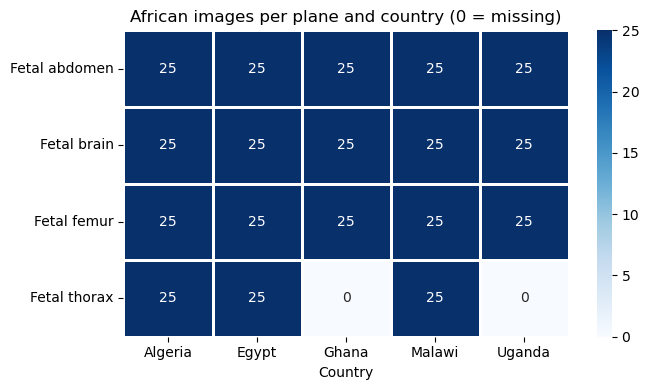

In [11]:
counts = pd.crosstab(african_planes["Plane"], african_planes["Center"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", linewidths=1, ax=ax)
ax.set_title("African images per plane and country (0 = missing)")
ax.set_xlabel("Country")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(FIGURES / "fig1_1_missingness_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

Ghana and Uganda contributed no thorax images, which is why thorax is the smallest class in the African data.

### 2.3 Class distribution (Figure 1.2)

How many images each plane has in each dataset. The imbalance ratio is the size of the largest class divided by the smallest.

In [12]:
african_counts = african_planes["Plane"].value_counts().reindex(PLANES)
fetal_counts = fetal_planes["Plane"].value_counts().reindex(PLANES)

print("African imbalance ratio:", round(african_counts.max() / african_counts.min(), 2))
print("Spanish imbalance ratio:", round(fetal_counts.max() / fetal_counts.min(), 2))
pd.DataFrame({"African": african_counts, "Spanish": fetal_counts})

African imbalance ratio: 1.67
Spanish imbalance ratio: 4.35


,African,Spanish
Plane,,
Fetal abdomen,125,711
Fetal brain,125,3092
Fetal femur,125,1040
Fetal thorax,75,1718


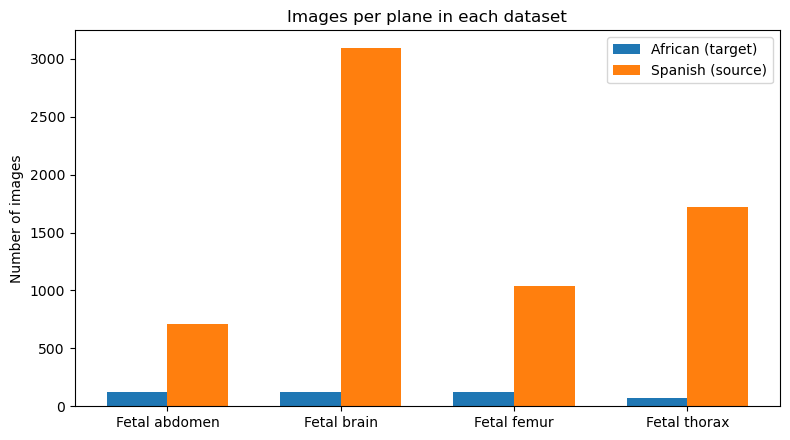

In [13]:
x = np.arange(len(PLANES))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, african_counts.values, width, label="African (target)")
ax.bar(x + width / 2, fetal_counts.values, width, label="Spanish (source)")
ax.set_xticks(x, PLANES)
ax.set_ylabel("Number of images")
ax.set_title("Images per plane in each dataset")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / "fig1_2_target_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Understanding the images

### 3.1 Sample images

One random image for each plane and site, to see what the scans look like and how they differ between countries and machines.

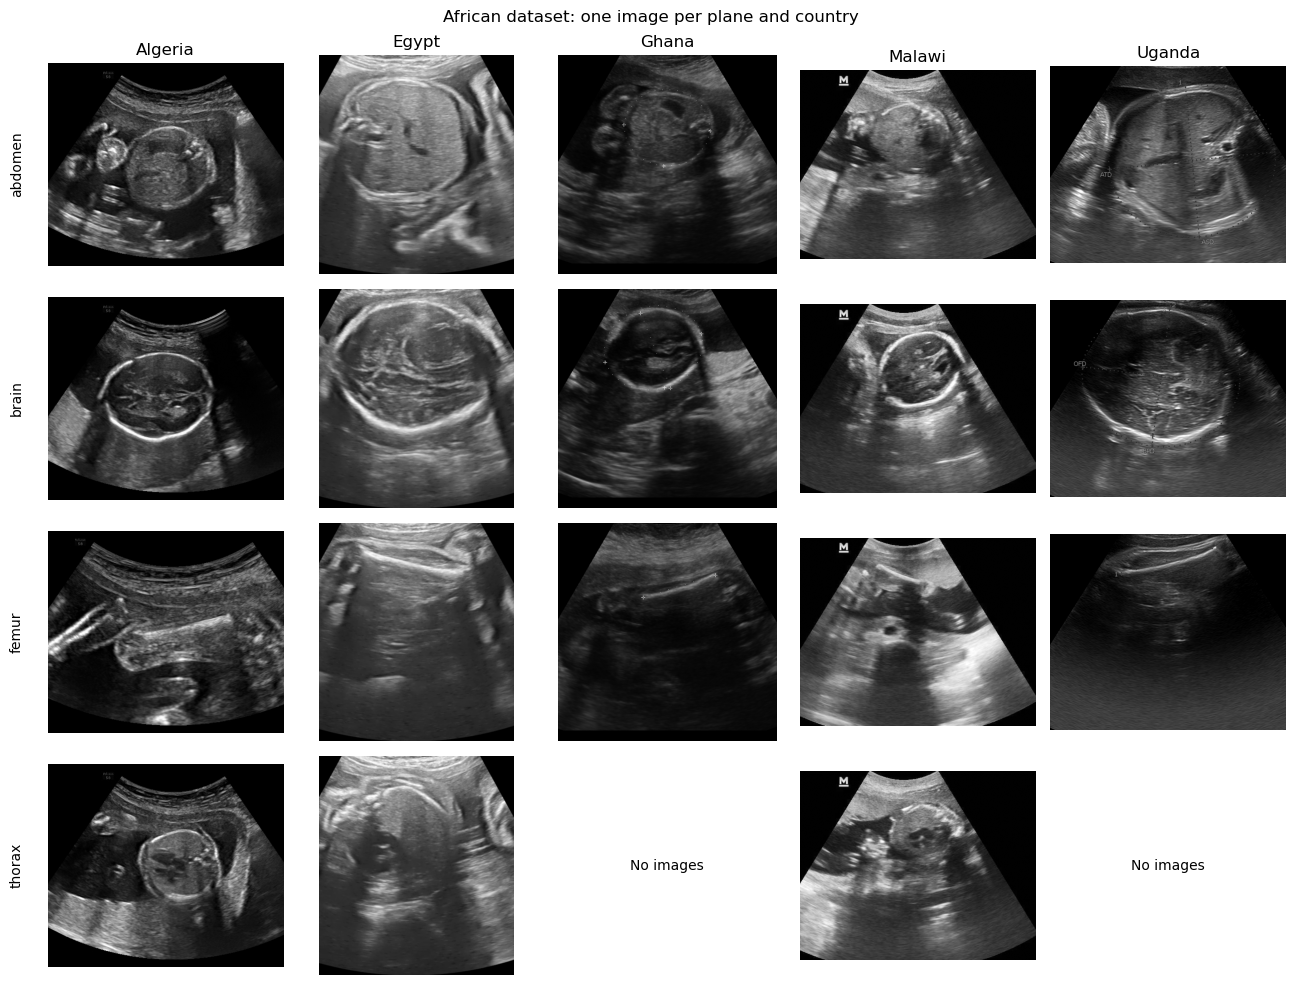

In [14]:
fig, axes = plt.subplots(4, 5, figsize=(13, 10))
for r, plane in enumerate(PLANES):
    for c, country in enumerate(CENTERS):
        ax = axes[r, c]
        ax.axis("off")
        subset = african_planes[(african_planes["Plane"] == plane) & (african_planes["Center"] == country)]
        if len(subset) > 0:
            row = subset.sample(1, random_state=random_seed).iloc[0]
            ax.imshow(Image.open(african_path(row)).convert("L"), cmap="gray")
        else:
            ax.text(0.5, 0.5, "No images", ha="center", va="center")
        if r == 0:
            ax.set_title(country)
        if c == 0:
            ax.text(-0.1, 0.5, plane.replace("Fetal ", ""), rotation=90, ha="right", va="center", transform=ax.transAxes)
fig.suptitle("African dataset: one image per plane and country")
plt.tight_layout()
plt.show()

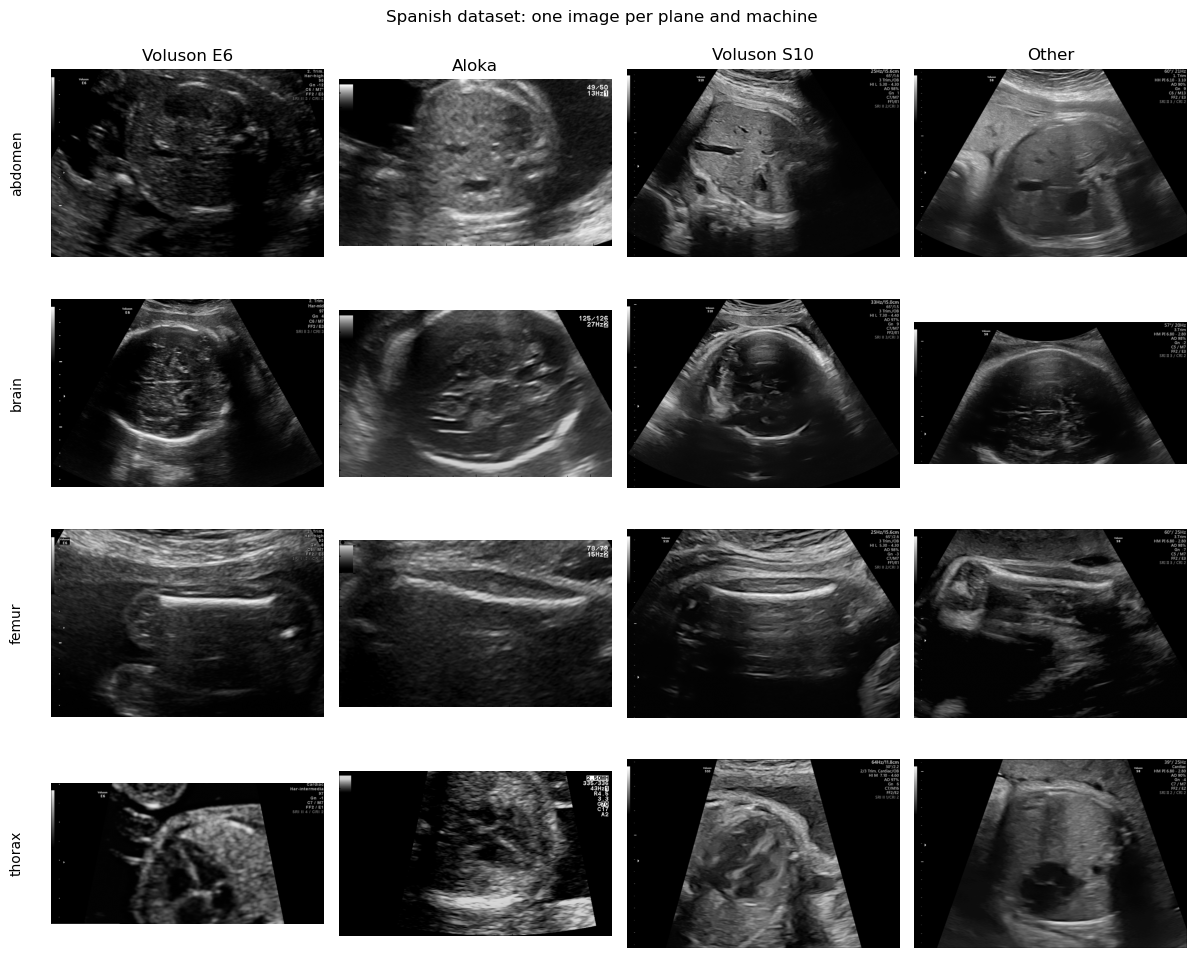

In [15]:
fig, axes = plt.subplots(4, 4, figsize=(12, 10))
for r, plane in enumerate(PLANES):
    for c, machine in enumerate(MACHINES):
        ax = axes[r, c]
        ax.axis("off")
        subset = fetal_planes[(fetal_planes["Plane"] == plane) & (fetal_planes["US_Machine"] == machine)]
        row = subset.sample(1, random_state=random_seed).iloc[0]
        ax.imshow(Image.open(fetal_path(row)).convert("L"), cmap="gray")
        if r == 0:
            ax.set_title(machine)
        if c == 0:
            ax.text(-0.1, 0.5, plane.replace("Fetal ", ""), rotation=90, ha="right", va="center", transform=ax.transAxes)
fig.suptitle("Spanish dataset: one image per plane and machine")
plt.tight_layout()
plt.show()

The scans differ visibly between sites: Malawi images carry a logo, Algerian images have text in the corners, Ghanaian and Ugandan images contain caliper marks, and each Spanish machine has its own screen layout. These marks reveal where an image was taken, not which plane it shows.

### 3.2 Image sizes

Image sizes in pixels (width × height) and how many images share each size.

In [16]:
def image_size(path):
    with Image.open(path) as image:
        return image.size

african_planes[["width", "height"]] = [image_size(african_path(row)) for _, row in african_planes.iterrows()]
fetal_planes[["width", "height"]] = [image_size(fetal_path(row)) for _, row in fetal_planes.iterrows()]

african_planes.groupby(["Center", "width", "height"]).size().reset_index(name="images")

,Center,width,height,images
0,Algeria,500,430,100
1,Egypt,400,450,100
2,Ghana,500,500,75
3,Malawi,500,400,100
4,Uganda,600,500,75


In [17]:
fetal_planes.groupby(["US_Machine", "width", "height"]).size().reset_index(name="images")

,US_Machine,width,height,images
0,Aloka,640,392,1165
1,Aloka,740,448,272
2,Other,1137,591,17
3,Other,1137,787,209
4,Other,1495,787,14
5,Voluson E6,959,496,202
6,Voluson E6,959,661,3349
7,Voluson E6,961,443,3
8,Voluson E6,961,498,8
9,Voluson E6,961,663,815


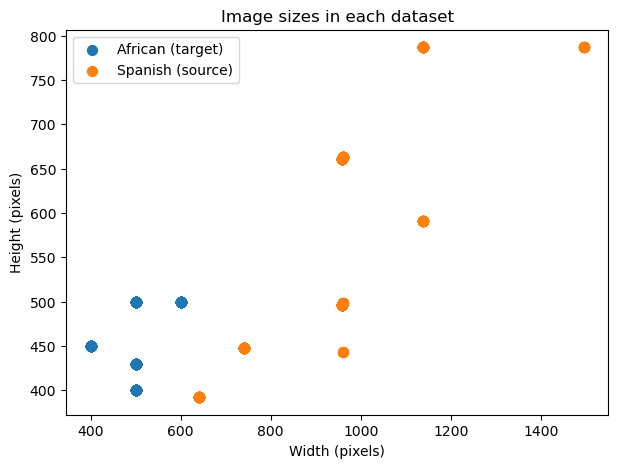

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(african_planes["width"], african_planes["height"], s=50, label="African (target)")
ax.scatter(fetal_planes["width"], fetal_planes["height"], s=50, label="Spanish (source)")
ax.set_xlabel("Width (pixels)")
ax.set_ylabel("Height (pixels)")
ax.set_title("Image sizes in each dataset")
ax.legend()
plt.show()

Each African country has exactly one image size, so the size alone reveals the country. The Spanish images are larger and much wider. All images will therefore need to be brought to one common size before training.

### 3.3 Brightness and contrast

Brightness is the average pixel value of an image (0 = black, 255 = white) and contrast is the standard deviation of its pixel values.

In [19]:
def brightness_contrast(path):
    with Image.open(path) as image:
        pixels = np.asarray(image.convert("L"), dtype=float)
    return pixels.mean(), pixels.std()

african_planes[["brightness", "contrast"]] = [brightness_contrast(african_path(row)) for _, row in african_planes.iterrows()]
fetal_planes[["brightness", "contrast"]] = [brightness_contrast(fetal_path(row)) for _, row in fetal_planes.iterrows()]

pd.DataFrame({"African": african_planes[["brightness", "contrast"]].mean(),
              "Spanish": fetal_planes[["brightness", "contrast"]].mean()}).round(1)

,African,Spanish
brightness,53.7,42.5
contrast,43.1,43.5


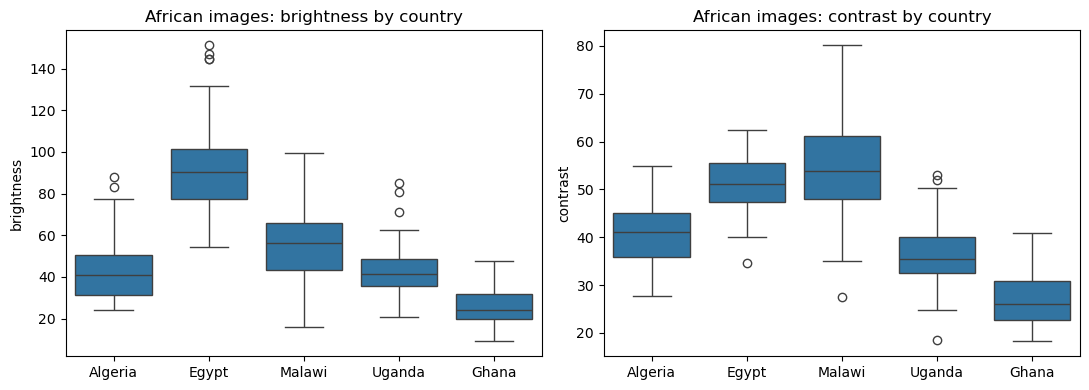

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["brightness", "contrast"]):
    sns.boxplot(data=african_planes, x="Center", y=column, ax=ax)
    ax.set_title(f"African images: {column} by country")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

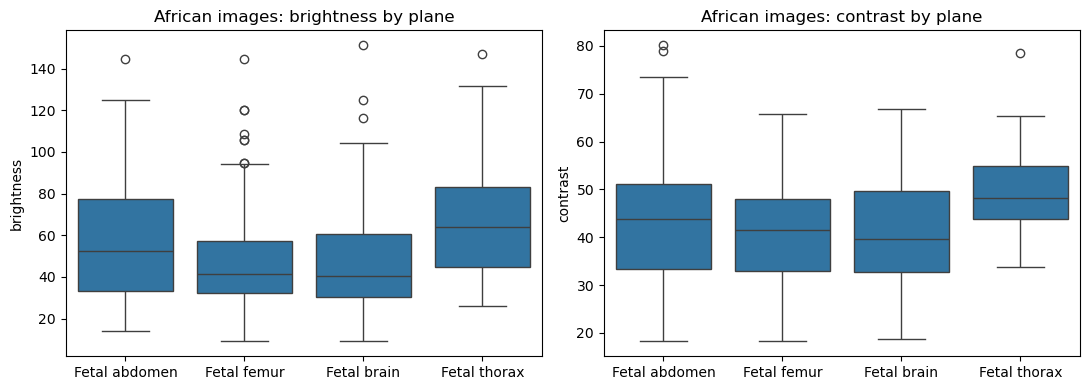

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["brightness", "contrast"]):
    sns.boxplot(data=african_planes, x="Plane", y=column, ax=ax)
    ax.set_title(f"African images: {column} by plane")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

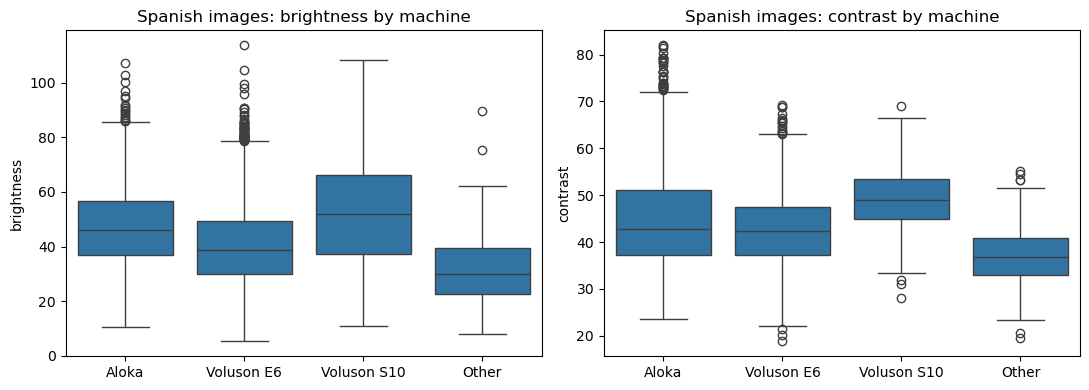

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["brightness", "contrast"]):
    sns.boxplot(data=fetal_planes, x="US_Machine", y=column, ax=ax)
    ax.set_title(f"Spanish images: {column} by machine")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

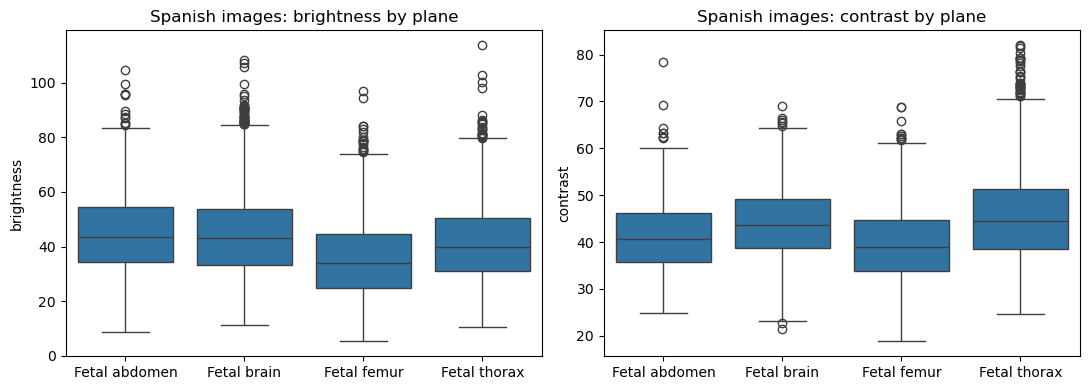

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, column in zip(axes, ["brightness", "contrast"]):
    sns.boxplot(data=fetal_planes, x="Plane", y=column, ax=ax)
    ax.set_title(f"Spanish images: {column} by plane")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Brightness varies far more between sites than between planes, so most of the differences come from the equipment and settings rather than the anatomy.

### 3.4 Pixel values

The distribution of pixel values for 20 random images per site. The tall spike at 0 is the black background around the scan; a line shifted left means darker images and a line shifted right means brighter ones. The log scale keeps the rare bright pixels visible.

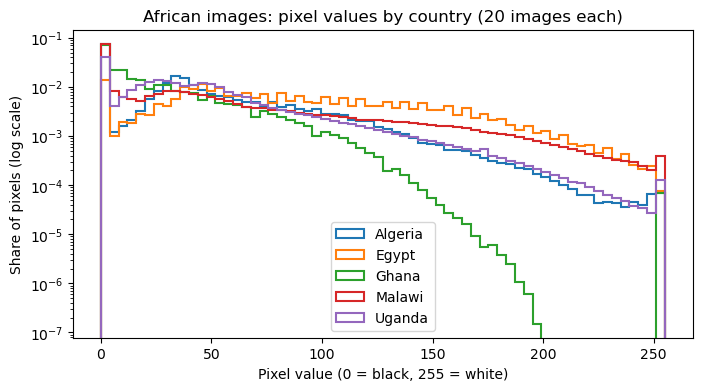

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
for country in CENTERS:
    subset = african_planes[african_planes["Center"] == country].sample(20, random_state=random_seed)
    pixels = np.concatenate([np.asarray(Image.open(african_path(row)).convert("L")).ravel()
                             for _, row in subset.iterrows()])
    ax.hist(pixels, bins=64, range=(0, 255), histtype="step", density=True, linewidth=1.5, label=country)
ax.set_yscale("log")
ax.set_xlabel("Pixel value (0 = black, 255 = white)")
ax.set_ylabel("Share of pixels (log scale)")
ax.set_title("African images: pixel values by country (20 images each)")
ax.legend()
plt.show()

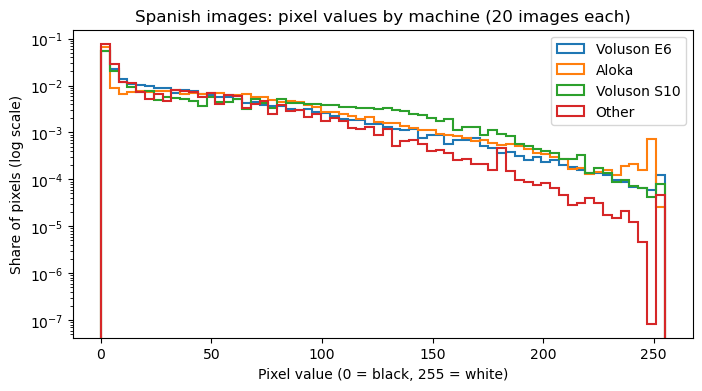

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
for machine in MACHINES:
    subset = fetal_planes[fetal_planes["US_Machine"] == machine].sample(20, random_state=random_seed)
    pixels = np.concatenate([np.asarray(Image.open(fetal_path(row)).convert("L")).ravel()
                             for _, row in subset.iterrows()])
    ax.hist(pixels, bins=64, range=(0, 255), histtype="step", density=True, linewidth=1.5, label=machine)
ax.set_yscale("log")
ax.set_xlabel("Pixel value (0 = black, 255 = white)")
ax.set_ylabel("Share of pixels (log scale)")
ax.set_title("Spanish images: pixel values by machine (20 images each)")
ax.legend()
plt.show()

## 4. Duplicate images

The same scan can appear more than once, sometimes filed under different patients. If one copy ends up in training and another in testing, the model is tested on an image it has already seen. Two kinds of hash are used to find copies:

- **MD5** gives every file a fingerprint. Two files with the same MD5 are byte-for-byte identical.
- **Perceptual hash** describes what an image looks like as 64 bits. Two images that look the same get almost the same bits, even if one was re-saved or slightly altered. The number of bits that differ (the Hamming distance) measures how similar they are: 0 means identical, and 4 or less is treated as a duplicate.

### 4.1 Hashing every image

The two hash functions (`md5_hash` and `image_phash`) are in `src/transformers.py`.

In [26]:
african_planes["md5"] = [md5_hash(african_path(row)) for _, row in african_planes.iterrows()]
african_planes["phash"] = [image_phash(african_path(row)) for _, row in african_planes.iterrows()]
fetal_planes["md5"] = [md5_hash(fetal_path(row)) for _, row in fetal_planes.iterrows()]
fetal_planes["phash"] = [image_phash(fetal_path(row)) for _, row in fetal_planes.iterrows()]

african_planes[["Filename", "md5", "phash"]].head()

,Filename,md5,phash
0,patient001_DZA_plane0,e5aee489694cdad7f8f63928f78ab803,10741372698832432807
1,patient001_DZA_plane2,155a1cbcdc924f7d477e8f6cc165369d,13916181582789423749
2,patient001_DZA_plane1,4ce38ab9a84a1be1226033070542849f,15348678043898960423
3,patient001_DZA_plane3,df7de87233caf7092eb098e20d966776,10521927031472417338
4,patient004_DZA_plane1,aeb8de6dd65b610be056a6f7137ebcc7,9534718186573619099


### 4.2 Identical copies

Images that share an MD5 or a perceptual hash exactly.

In [27]:
pd.DataFrame({
    "African": {"Identical files (MD5)": african_planes["md5"].duplicated(keep=False).sum(),
                "Identical look (perceptual hash)": african_planes["phash"].duplicated(keep=False).sum()},
    "Spanish": {"Identical files (MD5)": fetal_planes["md5"].duplicated(keep=False).sum(),
                "Identical look (perceptual hash)": fetal_planes["phash"].duplicated(keep=False).sum()},
})

,African,Spanish
Identical files (MD5),94,232
Identical look (perceptual hash),100,426


### 4.3 Near-copies in the African data

Every image is compared with every other image, and pairs within a distance of 4 are listed. For each pair the first image is kept and the second is removed.

In [28]:
def hash_distance(hash_a, hash_b):
    return bin(hash_a ^ hash_b).count("1")


pairs = []
hashes = african_planes["phash"].tolist()
for i in range(len(hashes)):
    for j in range(i + 1, len(hashes)):
        distance = hash_distance(hashes[i], hashes[j])
        if distance <= 4:
            pairs.append((i, j, distance))

african_pairs = pd.DataFrame(pairs, columns=["image_1", "image_2", "distance"])
african_pairs["file_1"] = african_planes.loc[african_pairs["image_1"], "Filename"].values
african_pairs["file_2"] = african_planes.loc[african_pairs["image_2"], "Filename"].values
african_pairs["same_label"] = (african_planes.loc[african_pairs["image_1"], "Plane"].values ==
                               african_planes.loc[african_pairs["image_2"], "Plane"].values)
print("Duplicate pairs:", len(african_pairs))
african_pairs.head(10)

Duplicate pairs: 54


,image_1,image_2,distance,file_1,file_2,same_label
0,4,44,0,patient004_DZA_plane1,patient031_DZA_plane1,True
1,5,46,0,patient004_DZA_plane2,patient031_DZA_plane2,True
2,6,47,0,patient004_DZA_plane3,patient031_DZA_plane3,True
3,7,45,0,patient004_DZA_plane0,patient031_DZA_plane0,True
4,8,54,0,patient007_DZA_plane2,patient034_DZA_plane2,True
5,9,52,0,patient007_DZA_plane3,patient034_DZA_plane3,True
6,10,55,0,patient007_DZA_plane1,patient034_DZA_plane1,True
7,11,53,0,patient007_DZA_plane0,patient034_DZA_plane0,True
8,16,68,0,patient014_DZA_plane1,patient041_DZA_plane1,True
9,17,71,0,patient014_DZA_plane2,patient041_DZA_plane2,True


In [29]:
drop = set(african_pairs["image_2"])
african_clean = african_planes.drop(index=list(drop)).reset_index(drop=True)
print("African images before:", len(african_planes), "| after:", len(african_clean))

African images before: 450 | after: 396


### 4.4 Near-copies in the Spanish data

With 6,561 images there are about 21 million pairs, so each image is compared with all the remaining images at once using numpy. Pairs whose copies carry different labels are a problem, because it is not possible to tell which label is correct, so both images are removed.

In [30]:
hashes = np.array(fetal_planes["phash"].tolist(), dtype=np.uint64)
pairs = []
for i in range(len(hashes)):
    distances = np.bitwise_count(hashes[i] ^ hashes[i + 1:])
    for j in np.nonzero(distances <= 4)[0]:
        pairs.append((i, i + 1 + j, int(distances[j])))

fetal_pairs = pd.DataFrame(pairs, columns=["image_1", "image_2", "distance"])
fetal_pairs["same_label"] = (fetal_planes.loc[fetal_pairs["image_1"], "Plane"].values ==
                             fetal_planes.loc[fetal_pairs["image_2"], "Plane"].values)
print("Duplicate pairs:", len(fetal_pairs))
print("Pairs with conflicting labels:", (~fetal_pairs["same_label"]).sum())

Duplicate pairs: 591
Pairs with conflicting labels: 4


In [31]:
conflicting = fetal_pairs[~fetal_pairs["same_label"]]
drop_conflicting = set(conflicting["image_1"]) | set(conflicting["image_2"])
drop_copies = set(fetal_pairs.loc[fetal_pairs["same_label"], "image_2"])

fetal_clean = fetal_planes.drop(index=list(drop_conflicting | drop_copies)).reset_index(drop=True)
print("Dropped for conflicting labels:", len(drop_conflicting))
print("Dropped as copies:", len(drop_copies - drop_conflicting))
print("Spanish images before:", len(fetal_planes), "| after:", len(fetal_clean))

Dropped for conflicting labels: 8
Dropped as copies: 494
Spanish images before: 6561 | after: 6059


### 4.5 Copies shared between the two datasets

No African image should also appear in the Spanish data, otherwise the model would see test images during pretraining.

In [32]:
fetal_hashes = np.array(fetal_clean["phash"].tolist(), dtype=np.uint64)
matches = 0
for h in african_clean["phash"]:
    if (np.bitwise_count(np.uint64(h) ^ fetal_hashes) <= 4).any():
        matches += 1
print("African images that also appear in the Spanish data:", matches)

African images that also appear in the Spanish data: 0


### Summary after cleaning

In [33]:
pd.DataFrame({
    "African (target)": {"Before": len(african_planes), "After": len(african_clean),
                         "Patients after": african_clean["patient_id"].nunique()},
    "Spanish (source)": {"Before": len(fetal_planes), "After": len(fetal_clean),
                         "Patients after": fetal_clean["patient_id"].nunique()},
})

,African (target),Spanish (source)
Before,450,6561
After,396,6059
Patients after,116,1155


## 5. Labels and splitting

### 5.1 Images per patient

Most patients contributed more than one image. Images from the same patient look very alike, so if some went to training and others to testing, the model would be tested on near-copies of what it learned from. This is why the split keeps all of a patient's images together.

In [34]:
images_per_patient = pd.DataFrame({
    "African": african_clean["patient_id"].value_counts().describe(),
    "Spanish": fetal_clean["patient_id"].value_counts().describe(),
}).round(1)
images_per_patient

,African,Spanish
count,116.0,1155.0
mean,3.4,5.2
std,0.7,2.8
min,1.0,1.0
25%,3.0,3.0
50%,3.5,5.0
75%,4.0,7.0
max,4.0,20.0


### 5.2 Encoding the labels

The plane names are turned into numbers the model can use: abdomen 0, brain 1, femur 2, thorax 3. The numbers are only identifiers and do not imply any order.

In [35]:
for df in (african_clean, fetal_clean):
    df["label"] = df["Plane"].map(LABELS)

print(LABELS)
pd.DataFrame({"African": african_clean["label"].value_counts().sort_index(),
              "Spanish": fetal_clean["label"].value_counts().sort_index()})

{'Fetal abdomen': 0, 'Fetal brain': 1, 'Fetal femur': 2, 'Fetal thorax': 3}


,African,Spanish
label,,
0,111,691
1,113,2963
2,111,1006
3,61,1399


### 5.3 Splitting the African data (80% development, 20% test)

`StratifiedGroupKFold` with 5 folds divides the data into 5 parts, and one part is taken as the test set, which gives about 20%. Grouping by patient keeps all of a patient's images on the same side, and stratifying by label keeps a similar mix of planes on both sides. The test set is put aside and only used once, at the very end.

In [36]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_seed)
dev_index, test_index = next(splitter.split(african_clean, african_clean["label"], african_clean["patient_id"]))

african_clean["partition"] = "development"
african_clean.loc[test_index, "partition"] = "test"
african_clean["partition"].value_counts()

partition
development    321
test            75
Name: count, dtype: int64

### 5.4 Splitting the Spanish data (85% training, 15% validation)

The Spanish data is only used for pretraining, so it needs a validation set to decide when to stop training, but no test set. Taking one of 7 parts gives about 15%.

In [37]:
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=random_seed)
train_index, val_index = next(splitter.split(fetal_clean, fetal_clean["label"], fetal_clean["patient_id"]))

fetal_clean["partition"] = "training"
fetal_clean.loc[val_index, "partition"] = "validation"
fetal_clean["partition"].value_counts()

partition
training      5220
validation     839
Name: count, dtype: int64

### 5.5 Checking the split

No patient should appear in more than one partition, and every country should be represented in the test set.

In [38]:
for name, df in [("African", african_clean), ("Spanish", fetal_clean)]:
    shared = (df.groupby("patient_id")["partition"].nunique() > 1).sum()
    print(f"{name}: patients in more than one partition = {shared}")

pd.crosstab(african_clean["Center"], african_clean["partition"])

African: patients in more than one partition = 0
Spanish: patients in more than one partition = 0


partition,development,test
Center,,
Algeria,60,16
Egypt,77,14
Ghana,57,18
Malawi,67,12
Uganda,60,15


### 5.6 Saving the cleaned tables

The cleaned and split tables are saved so later steps use exactly the same images and partitions.

In [39]:
african_clean.drop(columns=["md5", "phash"]).to_csv(PROCESSED / "african_clean.csv", index=False)
fetal_clean.drop(columns=["md5", "phash"]).to_csv(PROCESSED / "fetal_clean.csv", index=False)
print("Saved to", PROCESSED)

Saved to /Users/mac/Downloads/AISD/Project/fetal-ultrasound-plane-classification/data/processed


## 6. Fan mask (the ultrasound area)

The anatomy is only inside the fan-shaped scan area. The mask finds that area in four steps:

1. It keeps pixels brighter than 8, which separates the scan from the black background.
2. It removes small specks such as text and logos.
3. It keeps only the largest connected region, which is the fan.
4. It takes the convex hull of that region: the smallest shape without dents that encloses it. In dark images, dim tissue inside the fan falls below the threshold and would otherwise be cut away, so the hull restores the full fan outline.

The function lives in `src/transformers.py`; the cell below prints its code.

In [40]:
print(inspect.getsource(fan_mask))

def fan_mask(gray):
    """True inside the ultrasound fan, False outside it."""
    mask = ndimage.binary_opening(gray > 8, iterations=2)
    labels, n = ndimage.label(mask)
    largest = np.argmax(ndimage.sum(mask, labels, range(1, n + 1))) + 1
    return convex_hull_image(labels == largest)



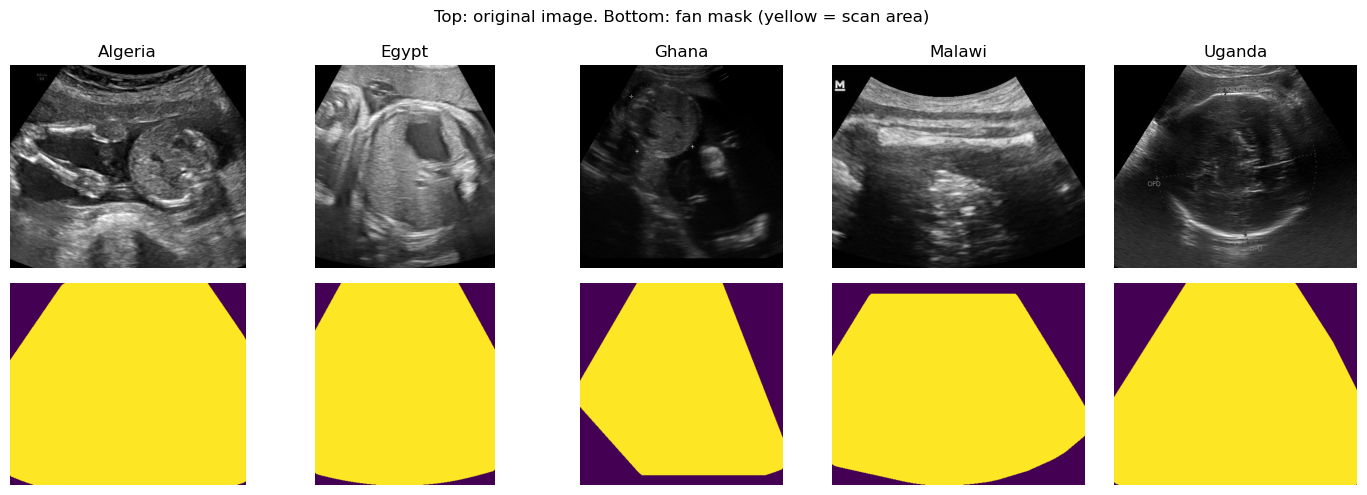

In [41]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for c, country in enumerate(CENTERS):
    row = african_clean[african_clean["Center"] == country].iloc[0]
    gray = np.asarray(Image.open(african_path(row)).convert("L"))
    axes[0, c].imshow(gray, cmap="gray")
    axes[0, c].set_title(country)
    axes[1, c].imshow(fan_mask(gray), cmap="viridis")
    for ax in axes[:, c]:
        ax.axis("off")
fig.suptitle("Top: original image. Bottom: fan mask (yellow = scan area)")
plt.tight_layout()
plt.show()

The fan mask is important because we don't want the model to learn how images from a specific region typically look, so that it does not associate images with regions. For example, Ghana does not have thorax. If the model is able to know how Ghana images typically look and know the planes, when a new image is uploaded that has the "Ghana" shape it can just assign the planes minus thorax, whereas the image was actually thorax.

## 7. Unusual images (outliers)

An outlier here is an image that is unusually dark or bright compared with other images from the **same country**. Each country used different equipment, so comparing a Ghanaian image with an Egyptian one would only flag whole countries rather than unusual images.

Brightness is measured **inside the fan only**, so the black background does not pull the average down. Only the **development set** is used: the test set stays untouched until the end, so nothing learned here can leak into the final evaluation.

In [42]:
development = african_clean[african_clean["partition"] == "development"].copy()
development["fan_brightness"] = [fan_brightness(african_path(row)) for _, row in development.iterrows()]
development["fan_brightness"].describe().round(1)

count    321.0
mean      65.0
std       26.8
min       18.0
25%       45.6
50%       61.1
75%       82.1
max      153.3
Name: fan_brightness, dtype: float64

### 7.1 Choosing the rule

There are two common rules for flagging outliers. The Z-score rule assumes the values follow a bell curve, while the IQR rule does not. Skewness measures how lopsided the values are (0 means symmetric), and excess kurtosis measures how heavy the tails are (0 for a bell curve, positive when extreme values are more common).

In [43]:
print("Skewness:", round(development["fan_brightness"].skew(), 2),
      "| excess kurtosis:", round(development["fan_brightness"].kurt(), 2))
development.groupby("Center")["fan_brightness"].agg(skewness="skew", kurtosis=pd.Series.kurt).round(2)

Skewness: 0.72 | excess kurtosis: 0.31


,skewness,kurtosis
Center,,
Algeria,0.22,-0.71
Egypt,0.57,0.17
Ghana,0.53,-0.56
Malawi,0.85,0.88
Uganda,1.20,1.94


### 7.2 IQR bounds per country

For each country, Q1 and Q3 are the brightness values a quarter and three quarters of the way up the sorted list, and the IQR is the gap between them. An image is flagged if it falls below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.

`SiteIQRFlagger` (in `src/transformers.py`) learns these bounds in `fit`, using the development set only, and applies them with `flag`.

In [44]:
flagger = SiteIQRFlagger().fit(development["fan_brightness"], development["Center"])
flagger.bounds_.round(1)

,Q1,Q3,IQR,lower bound,upper bound
Algeria,50.2,68.4,18.3,22.8,95.8
Egypt,77.3,103.9,26.7,37.2,144.0
Ghana,28.1,39.0,11.0,11.6,55.5
Malawi,60.8,87.2,26.5,21.1,126.9
Uganda,42.8,56.9,14.1,21.7,78.1


In [45]:
development["outlier"] = flagger.flag(development["fan_brightness"], development["Center"])

print("Flagged:", development["outlier"].sum(), "of", len(development), "development images")
development.loc[development["outlier"], ["Filename", "Center", "Plane", "fan_brightness"]]

Flagged: 9 of 321 development images


,Filename,Center,Plane,fan_brightness
163,patient028_EGY_plane2,Egypt,Fetal femur,146.550005
164,patient028_EGY_plane1,Egypt,Fetal brain,153.333288
165,patient028_EGY_plane3,Egypt,Fetal thorax,147.055381
166,patient028_EGY_plane0,Egypt,Fetal abdomen,146.667932
224,patient022_MWI_plane0,Malawi,Fetal abdomen,129.281748
239,patient033_MWI_plane0,Malawi,Fetal abdomen,138.689981
259,patient030_UGA_plane1,Uganda,Fetal brain,83.503677
278,patient050_UGA_plane0,Uganda,Fetal abdomen,94.592906
307,patient097_UGA_plane0,Uganda,Fetal abdomen,99.416197


### 7.3 Figure 2.1: brightness per country

Each box covers the middle half of a country's images, and the line inside is the median. The whiskers reach the IQR bounds, so every dot beyond them is a flagged image.

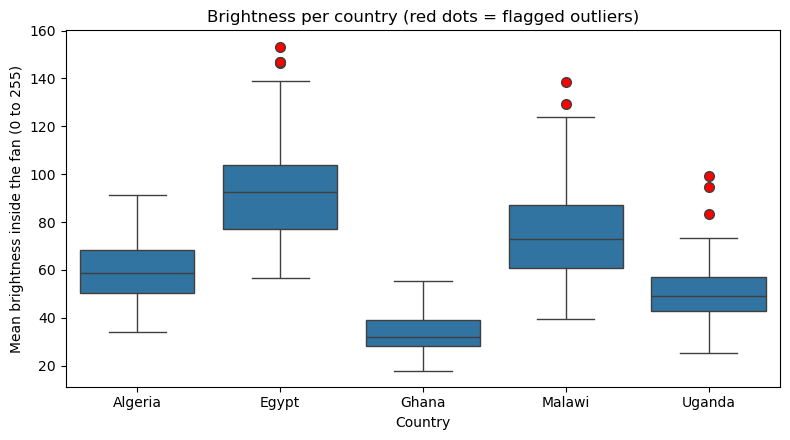

In [46]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=development, x="Center", y="fan_brightness", order=CENTERS, whis=1.5,
            flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 7}, ax=ax)
ax.set_xlabel("Country")
ax.set_ylabel("Mean brightness inside the fan (0 to 255)")
ax.set_title("Brightness per country (red dots = flagged outliers)")
plt.tight_layout()
plt.savefig(FIGURES / "fig2_1_outlier_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()

### 7.4 Looking at the flagged images

Before deciding what to do with them, the flagged images are checked by eye.

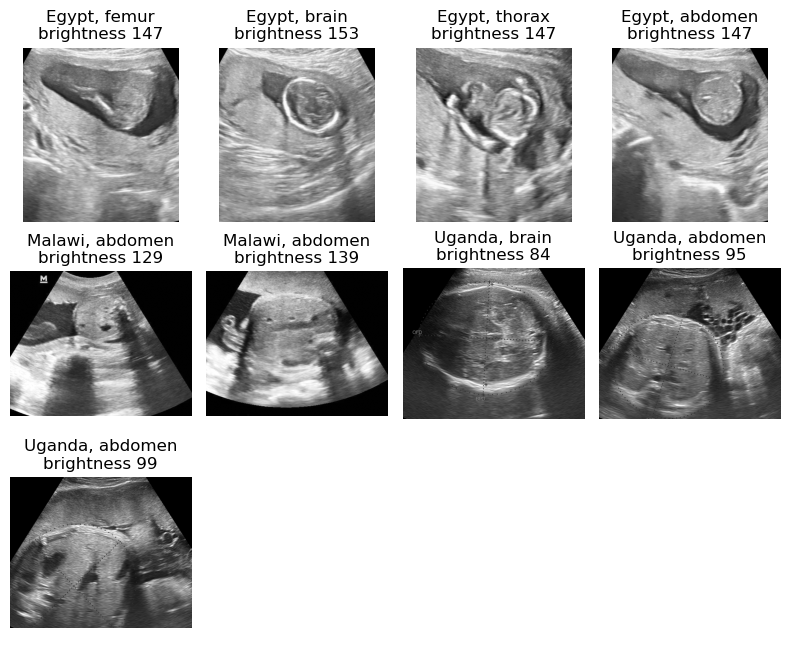

In [47]:
flagged = development[development["outlier"]]
columns = 4
rows = int(np.ceil(len(flagged) / columns))

fig, axes = plt.subplots(rows, columns, figsize=(2.0 * columns, 2.2 * rows))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, row) in zip(axes.ravel(), flagged.iterrows()):
    ax.imshow(Image.open(african_path(row)).convert("L"), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{row['Center']}, {row['Plane'].replace('Fetal ', '')}\nbrightness {row['fan_brightness']:.0f}")
plt.tight_layout()
plt.show()

### 7.5 Decision

9 of the 321 development images are flagged, and all of them are brighter than usual for their country; none is unusually dark. Four come from a single Egyptian patient, which suggests that whole session was scanned at a high brightness setting rather than that individual images are faulty. Five of the nine are abdomen scans, which tend to be brighter inside the fan, so deleting outliers would remove abdomen images unfairly.

The flagged images are therefore kept. None of them is corrupted or blank, the anatomy is still visible, and over-exposed scans are what the tool will meet in real clinics. Deleting them would also shrink an already small dataset. Extreme pixel values are instead handled in section 9 by trimming each image to its own 1st and 99th percentiles.

## 8. Image measurements and collinearity

The model will learn from the images themselves, but a few simple measurements make it possible to describe the images in numbers, compare them statistically, and check whether any two measurements say the same thing. Eight measurements are taken from each development image:

| Measurement | What it describes |
|---|---|
| brightness | average pixel value inside the fan |
| contrast | how spread out the pixel values are inside the fan |
| entropy | how varied the pixel values are (a flat image has low entropy) |
| sharpness | how crisp the edges are inside the fan |
| fan area | share of the image covered by the fan |
| width, height | image size in pixels |
| aspect ratio | width divided by height |

As in section 7, only the development set is used.

In [48]:
measurements = pd.DataFrame([measure(african_path(row)) for _, row in development.iterrows()],
                            index=development.index)
measurements.describe().round(2)

,brightness,contrast,entropy,sharpness,fan_area,width,height,aspect_ratio
count,321.00,321.00,321.00,321.00,321.00,321.00,321.00,321.00
mean,65.04,40.29,6.85,342.26,0.80,494.70,454.05,1.09
std,26.84,10.70,0.49,172.46,0.14,65.22,38.68,0.14
min,17.97,13.98,5.13,20.81,0.19,400.00,400.00,0.89
25%,45.58,31.52,6.51,188.47,0.72,500.00,430.00,1.00
50%,61.10,41.12,6.91,332.22,0.84,500.00,450.00,1.16
75%,82.08,48.32,7.24,451.29,0.93,500.00,500.00,1.20
max,153.33,69.83,7.85,801.69,1.00,600.00,500.00,1.25


### 8.1 How the measurements relate to each other (Figure 3.1)

Spearman correlation measures how strongly two measurements rise and fall together, from −1 to +1. It is used instead of Pearson correlation because several measurements are skewed (section 7.1). Only the lower triangle is shown, since the upper half would repeat it.

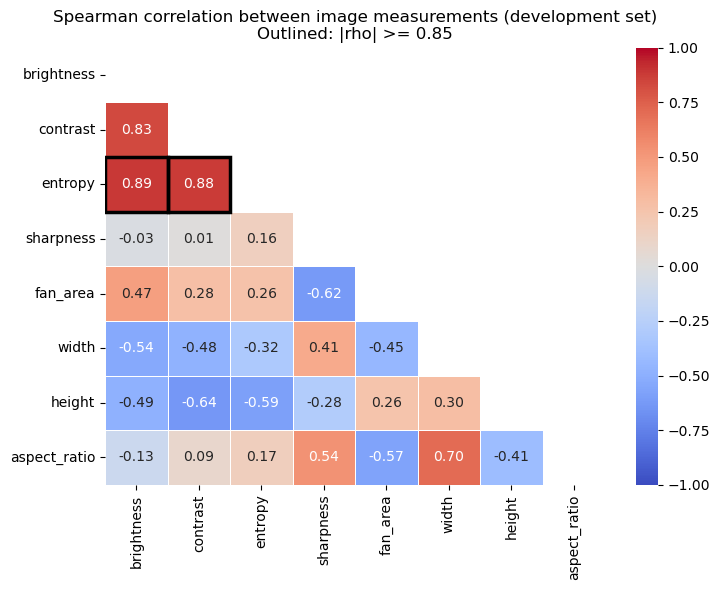

In [49]:
rho = measurements.corr(method="spearman")
upper_half = np.triu(np.ones_like(rho, dtype=bool))

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(rho, mask=upper_half, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
for r in range(len(rho)):
    for c in range(r):
        if abs(rho.iloc[r, c]) >= 0.85:
            ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor="black", linewidth=2.5))
ax.set_title("Spearman correlation between image measurements (development set)\nOutlined: |rho| >= 0.85")
plt.tight_layout()
plt.savefig(FIGURES / "fig3_1_correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.2 The most strongly related pair (Figure 3.2)

The pair with the strongest correlation, plotted image by image and coloured by country, with a fitted straight line for comparison.

Strongest pair: brightness and entropy (rho = 0.89)


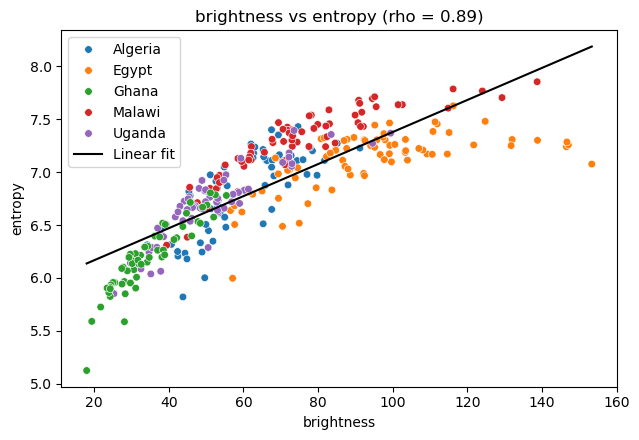

In [50]:
pairs = rho.where(np.triu(np.ones_like(rho, dtype=bool), k=1)).abs().stack()
first, second = pairs.idxmax()
print(f"Strongest pair: {first} and {second} (rho = {rho.loc[first, second]:.2f})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.scatterplot(x=measurements[first], y=measurements[second], hue=development["Center"],
                hue_order=CENTERS, s=30, ax=ax)
slope, intercept = np.polyfit(measurements[first], measurements[second], 1)
line_x = np.linspace(measurements[first].min(), measurements[first].max(), 50)
ax.plot(line_x, slope * line_x + intercept, color="black", linewidth=1.5, label="Linear fit")
ax.legend()
ax.set_title(f"{first} vs {second} (rho = {rho.loc[first, second]:.2f})")
plt.tight_layout()
plt.savefig(FIGURES / "fig3_2_collinear_scatterplots.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.3 How much each measurement says about the plane (Figure 3.3)

Mutual information measures how much knowing a measurement reduces uncertainty about the plane. It is 0 when the measurement tells us nothing, and it captures any kind of relationship, not only straight-line ones.

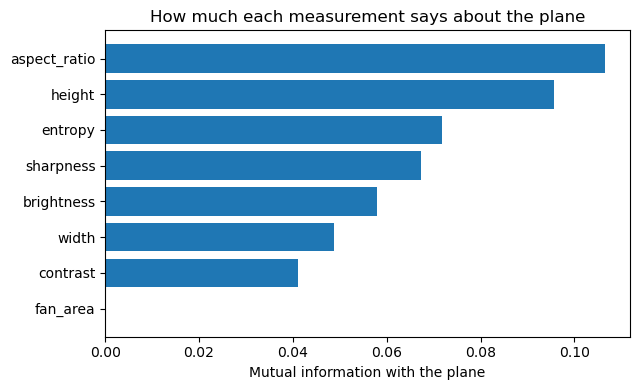

In [51]:
mi = pd.Series(mutual_info_classif(measurements, development["label"], random_state=random_seed),
               index=measurements.columns).sort_values()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.barh(mi.index, mi.values)
ax.set_xlabel("Mutual information with the plane")
ax.set_title("How much each measurement says about the plane")
plt.tight_layout()
plt.savefig(FIGURES / "fig3_3_target_importance.png", dpi=300, bbox_inches="tight")
plt.show()

### 8.4 Removing measurements that repeat each other

Two rules from the preprocessing strategy are applied in turn:

1. **Pairs:** if two measurements have an absolute Spearman correlation of 0.85 or more, the one with lower mutual information is dropped.
2. **VIF:** the variance inflation factor shows how well a measurement can be predicted from all the others combined. While any measurement has a VIF above 10, the one among them with the lowest mutual information is dropped and the VIFs are recalculated.

Both rules are implemented in `drop_collinear` in `src/transformers.py`.

Both rules live in a `CollinearityDropper` transformer, which sits inside the `ColumnTransformer` built by `build_feature_transformer` in `src/pipeline_builder.py`, followed by a `StandardScaler`. Fitting it on the development set lets the transformer learn which measurements to keep and the scaler learn their mean and standard deviation, so nothing is learned from the test set.

In [52]:
feature_transformer = build_feature_transformer(list(measurements.columns), max_rho=0.85, max_vif=10,
                                                random_state=random_seed)
feature_transformer.fit(measurements, development["label"])

dropper = feature_transformer.named_transformers_["measurements"].named_steps["drop_collinear"]
kept, dropped = dropper.kept_, dropper.dropped_
print("Dropped:", dropped)
print("Kept:", kept)
pd.DataFrame({"VIF before": vif_table(measurements), "VIF after": vif_table(measurements[kept])}).round(2)

Dropped: {'brightness': '|rho| = 0.89 with entropy', 'contrast': '|rho| = 0.88 with entropy', 'width': 'VIF = 478.9'}
Kept: ['entropy', 'sharpness', 'fan_area', 'height', 'aspect_ratio']


,VIF before,VIF after
aspect_ratio,503.76,1.60
brightness,5.30,NaN
contrast,6.25,NaN
entropy,8.87,2.62
fan_area,2.65,2.36
height,250.49,2.02
sharpness,2.15,2.10
width,506.04,NaN


### 8.5 Scaling the kept measurements

The kept measurements use different units (pixel values, pixels, ratios), so the same `ColumnTransformer` standardises them to a mean of 0 and a standard deviation of 1, using the development set's statistics.

In [53]:
scaled_measurements = pd.DataFrame(feature_transformer.transform(measurements), columns=kept,
                                   index=measurements.index)
scaled_measurements.agg(["mean", "std"]).round(2)

,entropy,sharpness,fan_area,height,aspect_ratio
mean,-0.0,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


### 8.6 How strongly site is tied to the plane

Chi-square tests whether two categories are related, and Cramér's V measures how strongly, from 0 (no relationship) to 1 (one fully decides the other). Here they measure how much the site (country, machine or operator) is entangled with the plane.

In [54]:
spanish_training = fetal_clean[fetal_clean["partition"] == "training"]
pd.DataFrame({
    "Country (African development)": cramers_v(development["Center"], development["Plane"]),
    "Machine (Spanish training)": cramers_v(spanish_training["US_Machine"], spanish_training["Plane"]),
    "Operator (Spanish training)": cramers_v(spanish_training["Operator"], spanish_training["Plane"]),
}).T

,chi-square,dof,p-value,Cramér's V
Country (African development),35.6,12.0,3.696333e-04,0.19
Machine (Spanish training),138.3,9.0,2.338477e-25,0.09
Operator (Spanish training),246.1,9.0,6.582977e-48,0.13


### 8.7 What the measurements show

- **Repeated information:** brightness, contrast and entropy rise and fall together (|ρ| between 0.83 and 0.89), because brighter scans also have more varied pixel values. Entropy says more about the plane than the other two, so brightness and contrast are dropped. Width is then removed by the VIF rule (VIF ≈ 479), since width, height and aspect ratio come from only five image sizes. The five measurements that remain all have a VIF below 3.
- **Curved relationship:** brightness and entropy are related along a curve rather than a straight line (Figure 3.2), which is why Spearman rather than Pearson correlation is used.
- **The shortcut again:** aspect ratio and height are the two measurements most related to the plane (Figure 3.3), even though they describe the image format rather than the anatomy. Each country has a single image size, and Ghana and Uganda have no thorax images, so the format partly reveals the plane. This is one reason every image is cropped and resized to the same size in section 9.
- **Site and plane:** country, machine and operator are all significantly associated with the plane (p < 0.001), but the strength of the association is weak (Cramér's V between 0.09 and 0.19).

## 9. Standardising the images

Every image goes through the same steps so that all images share one format, whatever machine produced them:

1. **Grayscale:** the Egyptian RGB images are converted to one channel; their three channels are identical, so nothing is lost.
2. **Fan mask:** everything outside the fan is set to black, removing logos and text (section 6).
3. **Crop to the fan:** the empty border around the fan is cut away.
4. **Trim extreme pixels:** pixel values inside the fan are limited to that image's own 1st and 99th percentiles. This is the treatment for the bright outliers found in section 7, and it also dims the brightest marks.
5. **Pad and resize:** the image is padded with black to a square and resized to 224 × 224, so no anatomy is stretched.

Every step uses only the image itself, so nothing is learned from other images and no information can leak between the development and test sets.

The functions for steps 3 to 5 are in `src/transformers.py`; the cell below prints their code.

In [55]:
for step in (crop_to_fan, trim_extremes, pad_and_resize):
    print(inspect.getsource(step))

def crop_to_fan(gray, mask):
    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]
    return gray[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1], mask[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]

def trim_extremes(gray, mask, low=1, high=99):
    low_value, high_value = np.percentile(gray[mask], [low, high])
    trimmed = np.clip(gray, low_value, high_value)
    trimmed[~mask] = 0
    return trimmed.astype(np.uint8)

def pad_and_resize(gray, size=224):
    height, width = gray.shape
    side = max(height, width)
    square = np.zeros((side, side), dtype=np.uint8)
    top, left = (side - height) // 2, (side - width) // 2
    square[top:top + height, left:left + width] = gray
    return np.asarray(Image.fromarray(square).resize((size, size), Image.BILINEAR))



### 9.1 The steps on one image per country (Figure 4.1)

Each row follows one image through the pipeline.

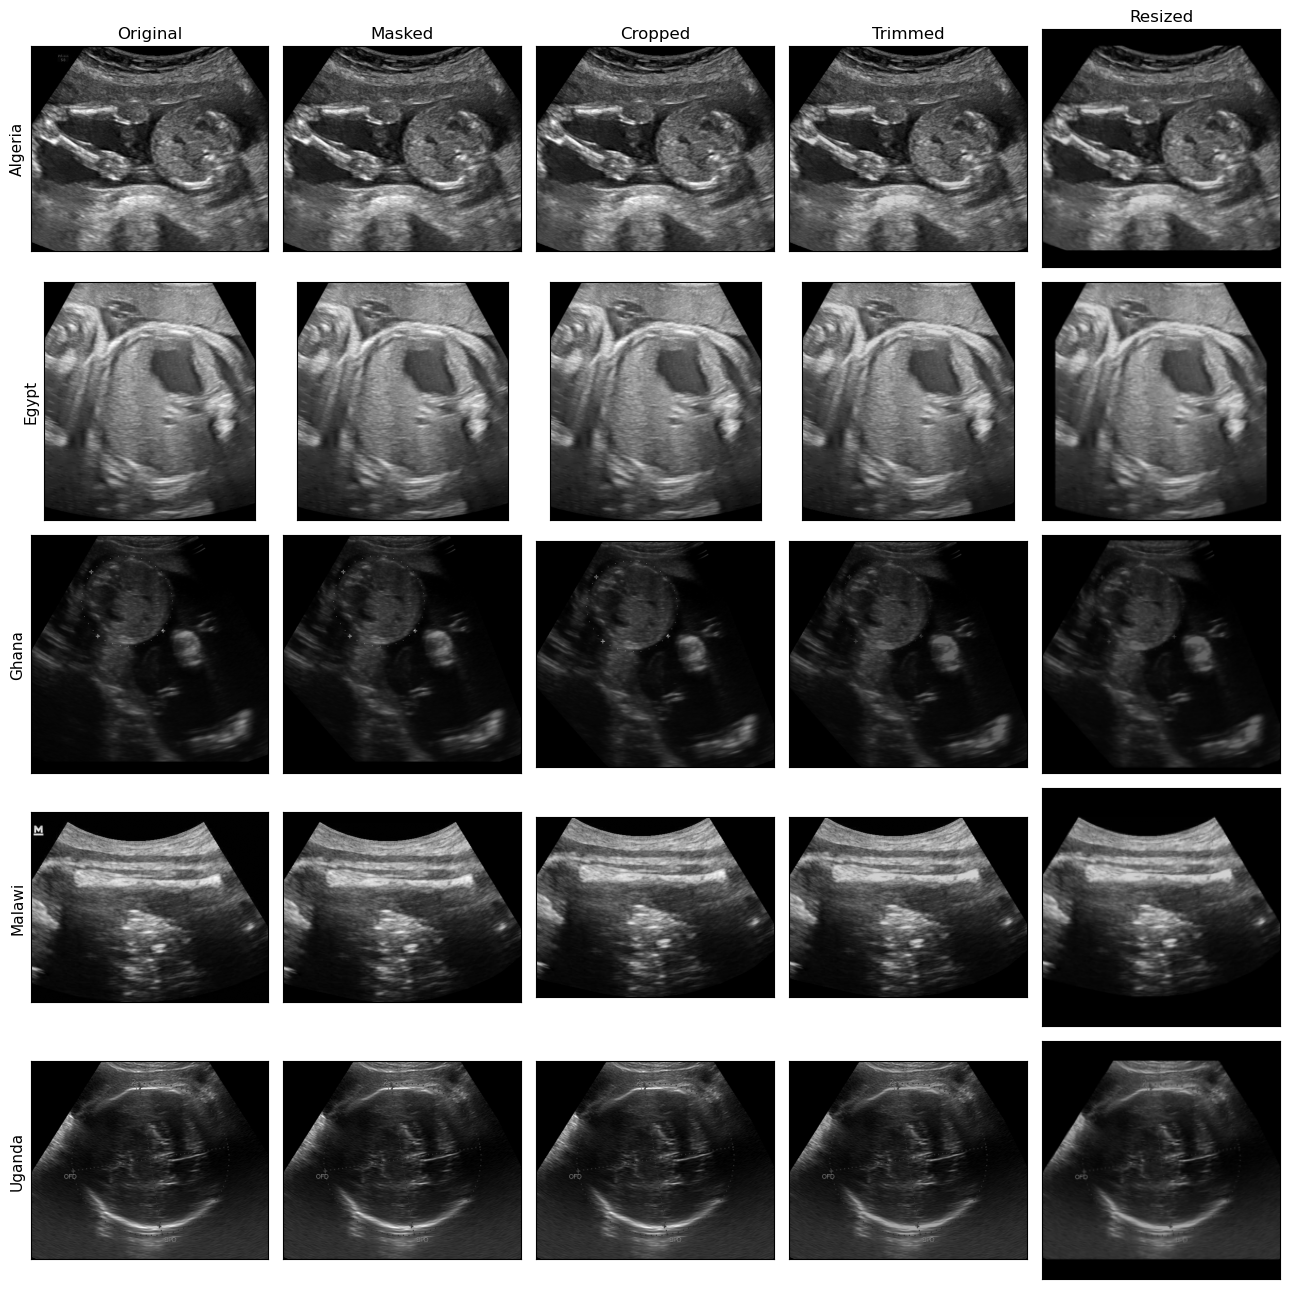

In [56]:
steps = ["original", "masked", "cropped", "trimmed", "resized"]
fig, axes = plt.subplots(len(CENTERS), len(steps), figsize=(13, 13))
for r, country in enumerate(CENTERS):
    row = african_clean[african_clean["Center"] == country].iloc[0]
    images = standardise_steps(african_path(row))
    for c, step in enumerate(steps):
        ax = axes[r, c]
        ax.imshow(images[step], cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([])
        ax.set_yticks([])
        if r == 0:
            ax.set_title(step.capitalize())
        if c == 0:
            ax.set_ylabel(country, fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES / "fig4_1_transformation_grid.png", dpi=300, bbox_inches="tight")
plt.show()

### 9.2 The image pipeline

Each step is wrapped as a scikit-learn transformer in `src/transformers.py`, and `build_image_pipeline` in `src/pipeline_builder.py` chains them into one `Pipeline`: load as grayscale → fan mask → crop → trim → pad and resize. None of the steps learns anything in `fit`, so the same pipeline can be applied to training, validation and test images without any leakage.

In [57]:
image_pipeline = build_image_pipeline(size=224)
image_pipeline

Pipeline(steps=[('load', GrayscaleLoader()), ('mask', FanMasker()),
                ('crop', FanCropper()), ('trim', ExtremeTrimmer()),
                ('resize', PadResizer())])

### 9.3 Standardising every image

All cleaned images from both datasets are processed and saved, in the same order as the cleaned tables. The Spanish data takes a few minutes because there are about 6,000 images. The images are processed in batches of 200 so the original Spanish images never all sit in memory at once.

In [58]:
african_processed = transform_in_batches(image_pipeline, [african_path(row) for _, row in african_clean.iterrows()])
fetal_processed = transform_in_batches(image_pipeline, [fetal_path(row) for _, row in fetal_clean.iterrows()])

np.savez_compressed(PROCESSED / "african_processed.npz", images=african_processed)
np.savez_compressed(PROCESSED / "fetal_processed.npz", images=fetal_processed)
print("African:", african_processed.shape, "| Spanish:", fetal_processed.shape)

African: (396, 224, 224) | Spanish: (6059, 224, 224)


### 9.4 Scaling for the model

The processed images are stored as whole numbers from 0 to 255 to save space. When an image is given to the model, two more steps are applied:

- **Scaling to [0, 1]:** dividing by 255. Neural networks train best on small, bounded values.
- **Backbone standardisation:** the image is copied into three channels and standardised with the fixed ImageNet mean and standard deviation, because the pretrained backbone was trained on images scaled this way.

The ImageNet values are fixed constants, not statistics from this data, so this step also learns nothing from the training set. A log transform is not used, because ultrasound machines already compress the signal logarithmically.

In [59]:
example = to_model_input(african_processed[0])
print("Model input shape:", example.shape)
print("Value range:", round(example.min(), 2), "to", round(example.max(), 2))

Model input shape: (3, 224, 224)
Value range: -2.12 to 1.86


### 9.5 Pixel values at each stage (Figure 4.2)

Pixel statistics for 50 random development images at each stage: the raw pixels inside the fan, after trimming and resizing, after scaling to [0, 1], and after standardisation with the ImageNet constants (shown for the first channel). Pixels outside the fan are excluded, because the black background would dominate every statistic.

In [60]:
def fan_pixels(path):
    gray = np.asarray(Image.open(path).convert("L"))
    return gray[fan_mask(gray)]


sample = development.sample(50, random_state=random_seed)
raw_pixels = np.concatenate([fan_pixels(african_path(row)) for _, row in sample.iterrows()])
processed = african_processed[sample.index]
trimmed_pixels = processed[processed > 0]

stages = {
    "Raw (inside the fan)": raw_pixels.astype(float),
    "Trimmed and resized": trimmed_pixels.astype(float),
    "Scaled to [0, 1]": trimmed_pixels / 255.0,
    "Standardised (ImageNet)": (trimmed_pixels / 255.0 - 0.485) / 0.229,
}
pd.DataFrame({name: {"mean": v.mean(), "std": v.std(), "skewness": pd.Series(v).skew(),
                     "min": v.min(), "max": v.max()} for name, v in stages.items()}).T.round(2)

,mean,std,skewness,min,max
Raw (inside the fan),63.89,48.38,1.19,0.0,255.00
Trimmed and resized,65.38,48.28,1.08,1.0,254.00
"Scaled to [0, 1]",0.26,0.19,1.08,0.0,1.00
Standardised (ImageNet),-1.00,0.83,1.08,-2.1,2.23


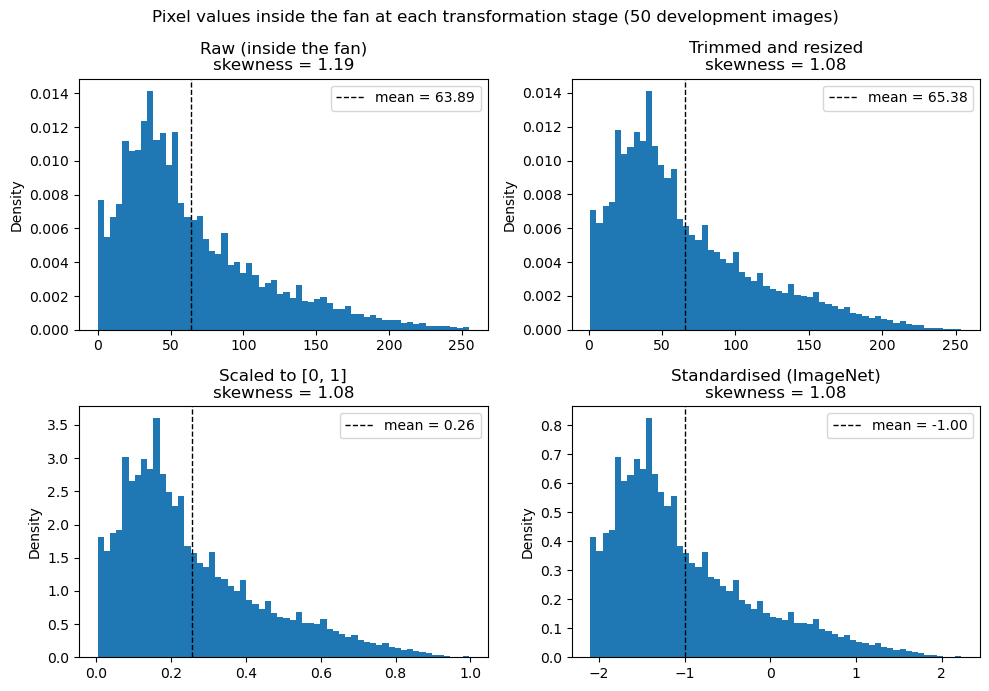

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (name, values) in zip(axes.ravel(), stages.items()):
    ax.hist(values, bins=60, density=True)
    ax.axvline(values.mean(), color="black", linestyle="--", linewidth=1, label=f"mean = {values.mean():.2f}")
    ax.set_title(f"{name}\nskewness = {pd.Series(values).skew():.2f}")
    ax.set_ylabel("Density")
    ax.legend()
fig.suptitle("Pixel values inside the fan at each transformation stage (50 development images)")
plt.tight_layout()
plt.savefig(FIGURES / "fig4_2_pixel_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 10. Image embeddings and PCA

A pretrained network (ResNet18, trained on ImageNet) turns each standardised image into 512 numbers that summarise its content, called an embedding. Principal component analysis (PCA) then asks how many combined directions are needed to keep most of the information in those 512 numbers. This is done on the African images only, which is enough to describe the target data and keeps the run time short.

The first run downloads the ResNet18 weights (about 45 MB).

In [62]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
backbone.fc = torch.nn.Identity()
backbone.eval()

embeddings = []
with torch.no_grad():
    for start in range(0, len(african_processed), 64):
        batch = np.stack([to_model_input(image) for image in african_processed[start:start + 64]])
        embeddings.append(backbone(torch.tensor(batch, dtype=torch.float32)).numpy())
embeddings = np.concatenate(embeddings)
print("Embeddings:", embeddings.shape)

Embeddings: (396, 512)


### 10.1 How many components are needed (Figure 5.1)

A `Pipeline` from `build_embedding_pca` standardises the embeddings and fits PCA, on the development images only. The bars show the share of variance explained by each component and the line the cumulative share; the table below gives the first eigenvalues.

Components for 90%: 96 | for 95%: 139 | out of 512


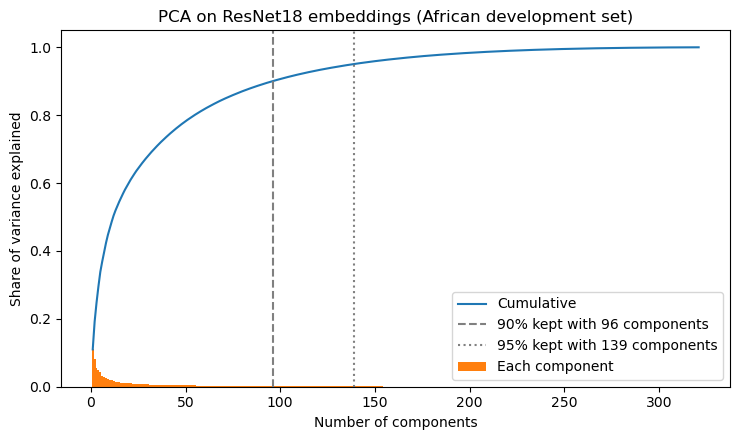

In [63]:
development_rows = (african_clean["partition"] == "development").to_numpy()
embedding_pca = build_embedding_pca().fit(embeddings[development_rows])
embedding_scaler = embedding_pca.named_steps["scale"]
pca = embedding_pca.named_steps["pca"]

cumulative = np.cumsum(pca.explained_variance_ratio_)
needed_90 = np.argmax(cumulative >= 0.90) + 1
needed_95 = np.argmax(cumulative >= 0.95) + 1
print("Components for 90%:", needed_90, "| for 95%:", needed_95, "| out of", embeddings.shape[1])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
components = np.arange(1, len(cumulative) + 1)
ax.bar(components, pca.explained_variance_ratio_, width=1.0, color="tab:orange", label="Each component")
ax.plot(components, cumulative, label="Cumulative")
for share, needed, style in [(0.90, needed_90, "--"), (0.95, needed_95, ":")]:
    ax.axvline(needed, linestyle=style, color="grey", label=f"{share:.0%} kept with {needed} components")
ax.legend(loc="lower right")
ax.set_xlabel("Number of components")
ax.set_ylabel("Share of variance explained")
ax.set_title("PCA on ResNet18 embeddings (African development set)")
plt.tight_layout()
plt.savefig(FIGURES / "fig5_1_pca_scree_plot.png", dpi=300, bbox_inches="tight")
plt.show()

In [64]:
pd.DataFrame({"eigenvalue": pca.explained_variance_[:5],
              "share of variance": pca.explained_variance_ratio_[:5],
              "cumulative": cumulative[:5]}, index=[f"PC{k}" for k in range(1, 6)]).round(3)

,eigenvalue,share of variance,cumulative
PC1,56.514999,0.110,0.110
PC2,41.925999,0.082,0.192
PC3,28.635000,0.056,0.247
PC4,24.590000,0.048,0.295
PC5,22.122999,0.043,0.338


### 10.2 What the curve shows

About 96 components are needed to keep 90% of the information and 139 to keep 95%, out of 512. The information is spread across many directions rather than concentrated in a few, so a small number of components would not summarise these images well. The curve stops at 321 components because PCA can find at most as many directions as there are development images.

## 11. Shortcut check

The initial data audit showed that the country can be guessed from an image far more easily than the plane, which is the acquisition shortcut. This check repeats that test before and after standardisation. Every development image is shrunk to a 32 × 32 thumbnail, and a simple model (logistic regression) tries to predict the country and the plane from it.

The scores come from five-fold cross-validation grouped by patient, so the model is always tested on patients it did not see. The scaler sits inside the pipeline, so it is refitted on the training part of every fold. The baseline is the score of always guessing the most common class.

In [65]:
def thumbnail(gray):
    return np.asarray(Image.fromarray(gray).resize((32, 32), Image.BILINEAR), dtype=float).ravel() / 255


def cv_accuracy(X, y):
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
    folds = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_seed)
    return cross_val_score(model, X, y, cv=folds, groups=development["patient_id"]).mean()


before = np.stack([thumbnail(np.asarray(Image.open(african_path(row)).convert("L")))
                   for _, row in development.iterrows()])
after = np.stack([thumbnail(image) for image in african_processed[development_rows]])

shortcut = pd.DataFrame({
    "Predicting the country": [cv_accuracy(before, development["Center"]),
                               cv_accuracy(after, development["Center"]),
                               development["Center"].value_counts(normalize=True).max()],
    "Predicting the plane": [cv_accuracy(before, development["Plane"]),
                             cv_accuracy(after, development["Plane"]),
                             development["Plane"].value_counts(normalize=True).max()],
}, index=["Before standardisation", "After standardisation", "Baseline (most common class)"])
(shortcut * 100).round(1)

,Predicting the country,Predicting the plane
Before standardisation,91.5,54.2
After standardisation,93.1,51.8
Baseline (most common class),24.0,28.0


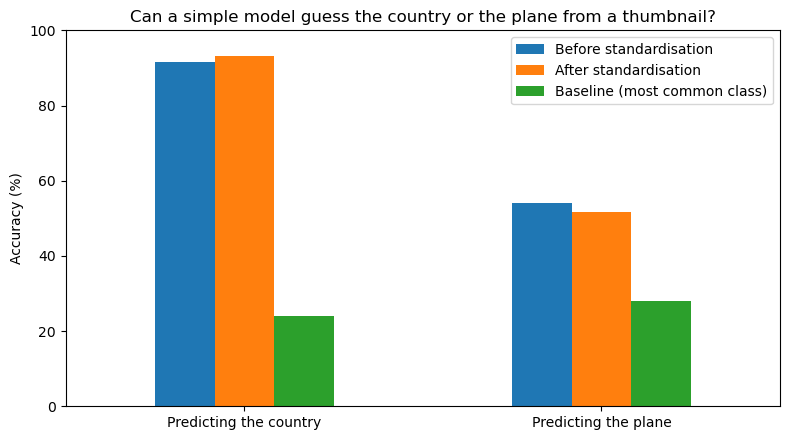

In [66]:
ax = (shortcut.T * 100).plot.bar(figsize=(8, 4.5), rot=0)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.set_title("Can a simple model guess the country or the plane from a thumbnail?")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

### 11.1 What the check shows

Standardisation did not remove the shortcut. After standardisation a simple model still guesses the country 93.1% of the time (91.5% before), while it guesses the plane only about 52% of the time, against baselines of 24% and 28%. Masking removes the logos and text, but other site signals remain: each scanner produces a fan with a characteristic outline, which fills the frame once the image is cropped, and overall brightness and texture still differ between sites (sections 3.3 and 7).

This is reported as a limitation rather than solved here. Augmentation (section 12) is designed to make brightness and image quality unreliable cues during training, and leave-one-country-out evaluation will measure how much the trained model relies on the site. A possible further step is to apply one common fan-shaped mask to every image, so that the outline no longer differs between sites.

## 12. Preparing for training: class weights and augmentation

### 12.1 Class weights

Thorax is the smallest African class and brain dominates the Spanish data. Instead of copying images, each class gets a weight in the loss function so that mistakes on rare classes count more. The weights are calculated from the training partitions only: the number of images divided by (number of classes × images in that class).

In [67]:
def class_weights(labels):
    weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=labels)
    return pd.Series(weights, index=PLANES).round(2)


pd.DataFrame({
    "African (development)": class_weights(development["label"]),
    "Spanish (training)": class_weights(spanish_training["label"]),
})

,African (development),Spanish (training)
Fetal abdomen,0.89,2.21
Fetal brain,0.89,0.51
Fetal femur,0.90,1.49
Fetal thorax,1.54,1.08


### 12.2 Augmentation

During training, each image is shown with small random changes, so that brightness, contrast, blur and noise stop being reliable clues to the machine, and the higher-quality Spanish images also come to resemble the range of quality seen in the African data. The changes are:

- brightness and contrast up to ±20%, and gamma between 0.8 and 1.2
- blur and speckle noise, imitating lower-quality equipment
- rotation up to ±10° and left–right flips

Vertical flips are not used, because the probe is always at the top of the image. Augmentation is applied to training images only, never to validation or test images.

The `augment` function is in `src/transformers.py`.

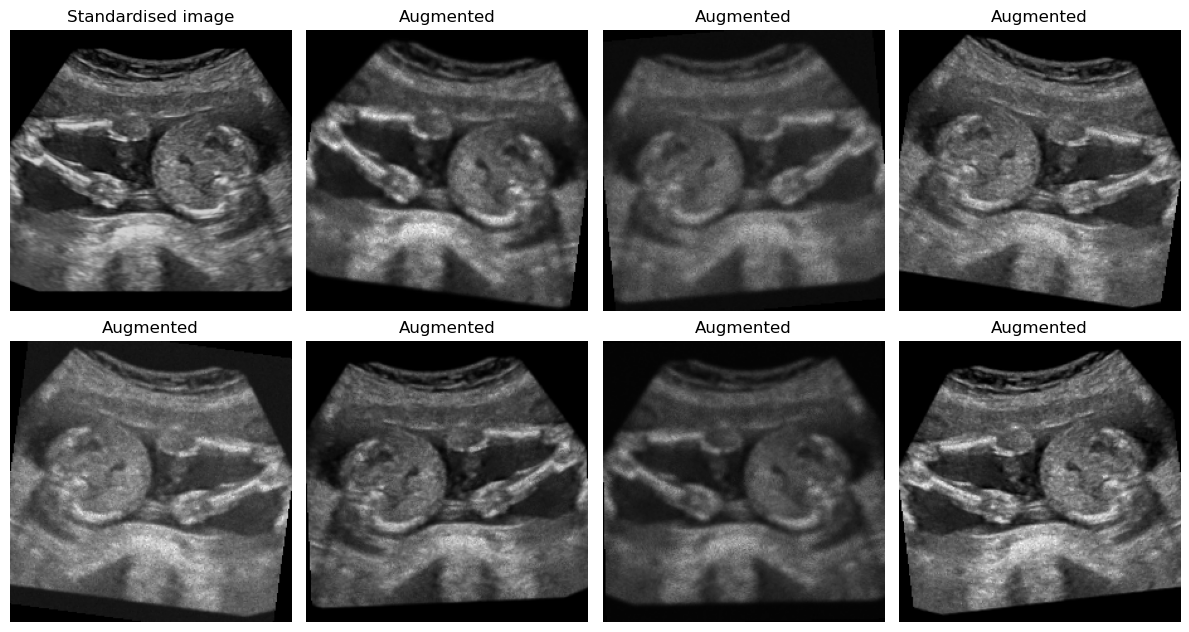

In [68]:
rng = np.random.default_rng(random_seed)


example = african_processed[0]
fig, axes = plt.subplots(2, 4, figsize=(12, 6.5))
axes[0, 0].imshow(example, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Standardised image")
for ax in axes.ravel()[1:]:
    ax.imshow(augment(example, rng), cmap="gray", vmin=0, vmax=255)
    ax.set_title("Augmented")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

## 13. Final checks

A last set of checks confirms that the pipeline did what the preprocessing strategy required: no patient or duplicate image is shared between partitions, every image comes out in the same format, and everything learned from the data was fitted on the development or training data only.

### 13.1 Near-duplicates across partitions

Duplicates were removed in section 4, before the split. This confirms that no two images within a distance of 4 ended up on different sides of the split.

In [69]:
def duplicates_across_partitions(df):
    hashes = np.array(df["phash"].tolist(), dtype=np.uint64)
    partitions = df["partition"].to_numpy()
    crossing = 0
    for i in range(len(hashes)):
        close = np.nonzero(np.bitwise_count(hashes[i] ^ hashes[i + 1:]) <= 4)[0] + i + 1
        crossing += (partitions[close] != partitions[i]).sum()
    return crossing


african_crossing = duplicates_across_partitions(african_clean)
fetal_crossing = duplicates_across_partitions(fetal_clean)
print("African duplicate pairs across partitions:", african_crossing)
print("Spanish duplicate pairs across partitions:", fetal_crossing)

African duplicate pairs across partitions: 0
Spanish duplicate pairs across partitions: 0


### 13.2 Checklist

Each check is either PASS or FAIL. The last three confirm that the scaler, PCA and outlier bounds saw only development images, so the test set had no influence on any fitted step.

In [70]:
def no_shared_patients(df):
    return (df.groupby("patient_id")["partition"].nunique() == 1).all()


def no_blank_images(images):
    return (images.reshape(len(images), -1).max(axis=1) > 0).all()


n_development = (african_clean["partition"] == "development").sum()
checks = {
    "No patient in two partitions (African)": no_shared_patients(african_clean),
    "No patient in two partitions (Spanish)": no_shared_patients(fetal_clean),
    "No duplicate across partitions (African)": african_crossing == 0,
    "No duplicate across partitions (Spanish)": fetal_crossing == 0,
    "No African image in the Spanish data": matches == 0,
    "One processed image per cleaned row": len(african_processed) == len(african_clean)
                                           and len(fetal_processed) == len(fetal_clean),
    "Every processed image is 224 x 224": african_processed.shape[1:] == (224, 224)
                                          and fetal_processed.shape[1:] == (224, 224),
    "No blank processed images": no_blank_images(african_processed) and no_blank_images(fetal_processed),
    "Model input is 3 x 224 x 224": to_model_input(african_processed[0]).shape == (3, 224, 224),
    "Outlier bounds fitted on development only": (development["partition"] == "development").all(),
    "Measurement scaler fitted on development only":
        feature_transformer.named_transformers_["measurements"].named_steps["scale"].n_samples_seen_ == n_development,
    "Embedding scaler and PCA fitted on development only":
        embedding_scaler.n_samples_seen_ == n_development and pca.n_samples_ == n_development,
}
pd.Series({name: "PASS" if passed else "FAIL" for name, passed in checks.items()}).to_frame("result")

,result
No patient in two partitions (African),PASS
No patient in two partitions (Spanish),PASS
No duplicate across partitions (African),PASS
No duplicate across partitions (Spanish),PASS
No African image in the Spanish data,PASS
One processed image per cleaned row,PASS
Every processed image is 224 x 224,PASS
No blank processed images,PASS
Model input is 3 x 224 x 224,PASS
Outlier bounds fitted on development only,PASS


### 13.3 Pipeline output

The data before and after the pipeline.

In [71]:
pd.DataFrame({
    "Before": ["450", "6,561 (four planes)", "Varied sizes, 1 or 3 channels", "8 measurements", "512 embedding values"],
    "After": [f"{len(african_clean)} ({n_development} development, {len(african_clean) - n_development} test)",
              f"{len(fetal_clean)} ({(fetal_clean['partition'] == 'training').sum()} training, "
              f"{(fetal_clean['partition'] == 'validation').sum()} validation)",
              "224 x 224 grayscale, given to the model as 3 x 224 x 224",
              f"{len(kept)} measurements ({', '.join(kept)})",
              f"{needed_95} components keep 95%"],
}, index=["African images", "Spanish images", "Image format", "Summary measurements", "Embeddings"])

,Before,After
African images,450,"396 (321 development, 75 test)"
Spanish images,"6,561 (four planes)","6059 (5220 training, 839 validation)"
Image format,"Varied sizes, 1 or 3 channels","224 x 224 grayscale, given to the model as 3 x..."
Summary measurements,8 measurements,"5 measurements (entropy, sharpness, fan_area, ..."
Embeddings,512 embedding values,139 components keep 95%
